# Homework 4 - Evaluation Metrics for Classification


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score


### Data preparation and split


In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

target = 'converted'
features = df.drop(columns=[target]).copy()
categorical = features.select_dtypes(include=['object', 'string']).columns.tolist()
numerical = features.select_dtypes(exclude=['object', 'string']).columns.tolist()

features[categorical] = features[categorical].fillna('NA')
features[numerical] = features[numerical].fillna(0.0)

df_prepared = features.assign(**{target: df[target].values})

df_full_train, df_test = train_test_split(df_prepared, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]


## Question 1: ROC AUC feature importance

Which numerical variable (among the 4 candidates) has the highest AUC?


In [3]:
candidates = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in candidates:
    score = roc_auc_score(y_train, df_train[col])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[col])
    print(f"{col}: {score:.4f}")


lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


## Question 2: Training the model

What's the AUC of this model on the validation dataset (rounded to 3 digits)?


In [4]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred)

print(f"Validation AUC: {round(val_auc, 3)}")


Validation AUC: 0.732


## Question 3: Precision and Recall

At which threshold precision and recall curves intersect?


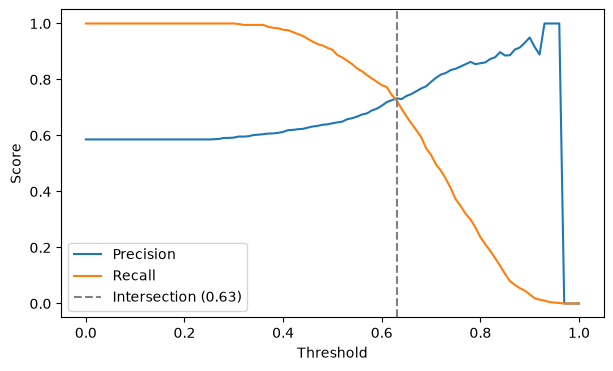

Intersection threshold: 0.63


In [5]:
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []
threshold_metrics = []

for t in thresholds:
    pred = (y_pred >= t).astype(int)
    p = precision_score(y_val, pred, zero_division=0)
    r = recall_score(y_val, pred, zero_division=0)
    precisions.append(p)
    recalls.append(r)
    if p > 0 or r > 0:
        threshold_metrics.append((abs(p - r), t))

intersect_threshold = min(threshold_metrics)[1]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.axvline(intersect_threshold, color='grey', linestyle='--', label=f'Intersection ({intersect_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

print(f"Intersection threshold: {intersect_threshold:.2f}")


## Question 4: F1 score

At which threshold F1 is maximal?


In [6]:
f1_scores = []

for t in thresholds:
    pred = (y_pred >= t).astype(int)
    score = f1_score(y_val, pred, zero_division=0)
    f1_scores.append((score, t))

best_f1, best_threshold = max(f1_scores, key=lambda x: x[0])
print(f"Max F1: {best_f1:.4f} at threshold: {best_threshold:.2f}")


Max F1: 0.7576 at threshold: 0.41


## Question 5: 5-Fold CV

How large is the standard deviation of the scores across different folds (rounded to 3 digits)?


In [7]:
def train_predict_fold(df_tr, y_tr, df_v):
    dv_fold = DictVectorizer(sparse=False)
    X_tr = dv_fold.fit_transform(df_tr.to_dict(orient='records'))
    X_v = dv_fold.transform(df_v.to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    m.fit(X_tr, y_tr)
    return m.predict_proba(X_v)[:, 1]

kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

df_full = df_full_train.reset_index(drop=True)
y_full = df_full[target].values
X_full = df_full.drop(columns=[target])

for train_idx, val_idx in kf.split(df_full):
    X_tr, X_v = X_full.iloc[train_idx], X_full.iloc[val_idx]
    y_tr, y_v = y_full[train_idx], y_full[val_idx]
    preds = train_predict_fold(X_tr, y_tr, X_v)
    scores.append(roc_auc_score(y_v, preds))

std_cv = np.std(scores)
print(f"Scores: {[round(s, 4) for s in scores]}")
print(f"Std: {round(std_cv, 3)}")


Scores: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Std: 0.007


## Question 6: Hyperparameter Tuning

Which C leads to the best mean ROC AUC?


In [8]:
for c in [0.000001, 0.001, 1]:
    c_scores = []
    for train_idx, val_idx in kf.split(df_full):
        X_tr, X_v = X_full.iloc[train_idx], X_full.iloc[val_idx]
        y_tr, y_v = y_full[train_idx], y_full[val_idx]
        dv_c = DictVectorizer(sparse=False)
        X_tr_mat = dv_c.fit_transform(X_tr.to_dict(orient='records'))
        X_v_mat = dv_c.transform(X_v.to_dict(orient='records'))
        m = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        m.fit(X_tr_mat, y_tr)
        preds = m.predict_proba(X_v_mat)[:, 1]
        c_scores.append(roc_auc_score(y_v, preds))
    print(f"C={c}: mean={round(np.mean(c_scores), 3)}, std={round(np.std(c_scores), 3)}")


C=1e-06: mean=0.617, std=0.019


C=0.001: mean=0.749, std=0.01


C=1: mean=0.732, std=0.007
